# Mathematics: Numerical Methods

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb) and knows what a derivative and an integral are, or a university student revising *Numerical Computing / Numerical Analysis* (a core course in HEC-pattern BS CS and BS AI programmes and a prerequisite for MS scientific computing).
>
> **What you will learn**
> - **Error analysis**: absolute and relative error, machine epsilon, truncation error versus round-off error, and well-conditioned versus unstable computations
> - **Root finding**: bisection, Newton–Raphson, secant and fixed-point iteration, with measured **orders of convergence** and the classic failure cases
> - **Interpolation**: Lagrange and Newton divided differences, **Runge's phenomenon**, Chebyshev nodes, and natural **cubic splines** from scratch
> - **Numerical differentiation**: forward and central differences, the **step-size trade-off curve**, the complex-step trick, and comparison with automatic differentiation (`torch.autograd`)
> - **Numerical integration**: trapezoid, Simpson, **Gauss–Legendre** (nodes computed from scratch), adaptive quadrature, and **Monte Carlo** integration with its $1/\sqrt{n}$ error
> - **ODE solvers**: Euler and **RK4**, global error order, **stability**, and a **stiff** equation solved with explicit and implicit methods (`scipy.integrate.solve_ivp`)
> - **Least-squares curve fitting** with `scipy.optimize.curve_fit`, parameter uncertainties and residual diagnostics
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb), [`02_calculus.ipynb`](02_calculus.ipynb) (derivatives, Taylor series, integrals) and [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) (floating-point numbers and cancellation; this notebook builds on it). Helpful: [`00_start_here_math_notation_bridge.ipynb`](00_start_here_math_notation_bridge.ipynb).
>
> **Time needed:** about 3 hours (reading, running, and the practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: numpy, pandas, matplotlib, scipy, and torch (only for one autodiff comparison). The whole notebook runs in under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Burden, Faires and Burden, *Numerical Analysis* (10th ed.), chapters 1 to 5 and 8, and Heath, *Scientific Computing: An Introductory Survey* (2nd ed., SIAM Classics 2018).

## Explained simply

Computers are brilliant at arithmetic but they cannot do algebra the way you do on paper. When there is no neat formula for the answer, we **approximate**: take small, simple steps that get closer and closer to the truth. Numerical methods are the recipes for those steps, and numerical *analysis* is knowing how wrong the answer can be and how fast it improves. Every number in a computer is rounded to about 16 significant digits, so we must also watch for small rounding errors that grow into big ones. Machine learning runs on these recipes: training a network is solving an equation step by step, and checking gradients is a numerical derivative.

**Everyday examples**
- Guessing a number between 1 and 100 by asking "higher or lower?" halves the range each time. That is the **bisection method** for finding where a function crosses zero.
- A sat-nav estimates your arrival time by adding up many short stretches of road at their speeds. That is **numerical integration**.
- A weather forecast moves the atmosphere forward in small time steps; if the steps are too big the forecast "explodes". That is **ODE stability**.

**A tiny concrete example.** Find $\sqrt{2}$ without a square-root button. Start with a guess $x = 1$. Replace $x$ by the average of $x$ and $2/x$: $1 \to 1.5 \to 1.41667 \to 1.4142157 \to 1.41421356237$. After 4 steps the answer is correct to 11 decimal places, because each step roughly doubles the number of correct digits. (This is Newton's method.)

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Root finding | Repeatedly improve a guess until an equation balances | Solving for interest rates, calibrating models, line searches in optimisers |
| Numerical integration | Add up many thin slices to get an area or average | Expected values, probability of an interval, physics simulations |
| ODE solver and stability | Move a system forward in small time steps without blowing up | Weather and physics simulation, Neural ODEs, why learning rates have a limit |

### How this notebook is different from its neighbours
- [`02_calculus.ipynb`](02_calculus.ipynb) teaches derivatives and integrals *symbolically*. Here we compute them when no formula is available, and measure how accurate the result is.
- [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) shows floating-point pitfalls in production code (cancellation, summation error, `solve` vs `inv`, a gradient check). Here we build the classical algorithms of numerical analysis and their error theory.
- [`05_Deep_Learning/10_neural_ode.ipynb`](../05_Deep_Learning/10_neural_ode.ipynb) uses ODE solvers inside neural networks. Section 7 here explains why those solvers work and when they fail.
- Linear systems, eigenvalues and sparse matrices come next, in [`10_numerical_linear_algebra.ipynb`](10_numerical_linear_algebra.ipynb).

## Table of contents
1. Error analysis
2. Root finding
3. Interpolation
4. Numerical differentiation
5. Numerical integration (quadrature)
6. Monte Carlo integration
7. Ordinary differential equations
8. Least-squares curve fitting
9. Summary table
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)
rng = np.random.default_rng(42)   # the modern NumPy random generator

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import scipy
from scipy import optimize, integrate, interpolate, stats
warnings.filterwarnings("ignore", category=RuntimeWarning)   # we create overflow on purpose in a few demos
print("scipy", scipy.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


scipy 1.18.0


---
## 1. Error analysis

> **In plain English:** before computing anything we need words for "how wrong is this answer?", and to know the two main reasons answers go wrong.

**Definitions.** If $x$ is the true value and $\hat x$ the computed one:
- **absolute error** $= |\hat x - x|$;
- **relative error** $= |\hat x - x| / |x|$ (for $x \ne 0$). A relative error of about $10^{-k}$ means roughly $k$ correct significant digits.

**Machine epsilon** $\varepsilon_{\text{mach}}$ is the gap between 1 and the next larger floating-point number. In IEEE-754 double precision (`float64`) it is $2^{-52} \approx 2.22 \times 10^{-16}$; every basic operation is correct to within a relative error of $\varepsilon_{\text{mach}}/2$ (the **unit roundoff**).

Two sources of error, which pull in opposite directions throughout this notebook:

| | **Truncation (discretisation) error** | **Round-off error** |
|---|---|---|
| Cause | replacing an infinite or continuous process by a finite one (cutting a Taylor series, a finite step $h$) | storing numbers with finitely many digits |
| Shrinks when | you take more terms / smaller steps | you take *fewer* operations, or avoid subtracting nearly equal numbers |
| Typical size | $O(h^p)$ for a method of order $p$ | $O(\varepsilon_{\text{mach}})$ per operation, amplified by cancellation |

Two more words: a *problem* is **ill-conditioned** if small changes in the input cause large changes in the exact answer (no algorithm can fix that), and an *algorithm* is **unstable** if it amplifies round-off more than the problem's conditioning requires (a better algorithm fixes it).

**Worked example: $e^{-20}$ from its Taylor series.** $e^x = \sum_{k \ge 0} x^k / k!$ converges for every $x$, so *mathematically* summing it at $x = -20$ is fine. Numerically, the terms reach about $4 \times 10^{7}$ in size with alternating signs and must cancel down to $2 \times 10^{-9}$: every digit of the answer is lost to round-off. Computing $1 / e^{20}$ instead (all terms positive, no cancellation) is accurate.

In [2]:
eps = np.finfo(float).eps
print(f"machine epsilon (float64) = {eps:.3e} = 2^{int(np.log2(eps))}")
print(f"1 + eps/2 == 1 ? {1 + eps / 2 == 1}     1 + eps == 1 ? {1 + eps == 1}")
print(f"float32 epsilon = {np.finfo(np.float32).eps:.3e} (about 7 significant digits)")

def exp_taylor(x, n_terms):
    term, total = 1.0, 1.0
    for k in range(1, n_terms):
        term *= x / k            # x^k / k!, built incrementally
        total += term
    return total

true = math.exp(-20)
rows = []
for n in [10, 30, 60, 100, 150]:
    direct = exp_taylor(-20, n)                 # alternating series: cancellation
    via_inverse = 1 / exp_taylor(20, n)         # positive series, then invert
    rows.append({"terms": n, "direct sum": direct, "rel. error direct": abs(direct - true) / true,
                 "1 / sum at +20": via_inverse, "rel. error inverse": abs(via_inverse - true) / true})
print(f"true e^-20 = {true:.6e}; largest term in the series = {20**20 / math.factorial(20):.3e}")
pd.DataFrame(rows).style.format({c: "{:.3e}" for c in rows[0] if c != "terms"})

machine epsilon (float64) = 2.220e-16 = 2^-52
1 + eps/2 == 1 ? True     1 + eps == 1 ? False
float32 epsilon = 1.192e-07 (about 7 significant digits)
true e^-20 = 2.061154e-09; largest term in the series = 4.310e+07


,terms,direct sum,rel. error direct,1 / sum at +20,rel. error inverse
0,10,-9.622e+05,4.668e+14,4.126e-07,1.992e+02
1,30,-2.448e+06,1.188e+15,2.107e-09,2.230e-02
2,60,-1.042e-04,5.057e+04,2.061e-09,4.230e-13
3,100,6.148e-09,1.983e+00,2.061e-09,4.013e-16
4,150,6.148e-09,1.983e+00,2.061e-09,4.013e-16


**What just happened?**
- With 10 terms both versions are wrong because of **truncation**: the series has been cut far too early.
- With enough terms, the inverse version converges to full double precision (relative error near $10^{-16}$), while the direct sum stalls at $6.1 \times 10^{-9}$, three times the true value (relative error about 2); with 60 terms it is even *negative*. Adding more terms cannot help, because the error is now **round-off**: the largest term is about $4.3 \times 10^7$, so its last digit is about $4.3 \times 10^7 \times 10^{-16} \approx 10^{-8}$, which is bigger than the answer $2 \times 10^{-9}$ itself.
- Lesson: the same mathematical formula can be a stable or an unstable *algorithm*.

> 🎓 **Exam / interview tip.** "Why is `0.1 + 0.2 != 0.3`?" and "What is machine epsilon?" are standard. Compare floats with a tolerance (`math.isclose`, `np.allclose`), never with `==`.

---
## 2. Root finding

> **In plain English:** find the $x$ where a function equals zero by improving a guess over and over, and measure how quickly the guesses improve.

Many problems have the form "find $x$ with $f(x) = 0$": the interest rate that makes a loan's present value zero, the threshold where precision equals recall, the step size in a line search. We use Newton's own 1669 test problem

$$f(x) = x^3 - 2x - 5, \qquad x^* \approx 2.0945514815423265.$$

**Order of convergence.** If $e_k = |x_k - x^*|$ and $e_{k+1} \approx C e_k^p$, the method has **order $p$**. Order 1 (linear) adds a fixed number of correct digits per step; order 2 (quadratic) *doubles* the number of correct digits per step. We can measure $p$ from three consecutive errors: $p \approx \log(e_{k+1}/e_k) / \log(e_k/e_{k-1})$.

| Method | Update | Needs | Order | Guaranteed? |
|---|---|---|---|---|
| **Bisection** | halve a bracket $[a, b]$ with $f(a) f(b) < 0$ | sign change | 1 (error halves) | yes, for continuous $f$ |
| **Newton–Raphson** | $x_{k+1} = x_k - f(x_k)/f'(x_k)$ | $f'$ | 2 (simple roots) | only near the root |
| **Secant** | Newton with $f'$ replaced by the slope through the last two points | two starting points | $\varphi = (1+\sqrt5)/2 \approx 1.618$ | only near the root |
| **Fixed point** | $x_{k+1} = g(x_k)$ where $x = g(x) \iff f(x) = 0$ | a good $g$ | 1, rate $\lvert g'(x^*)\rvert$; diverges if $\lvert g'(x^*)\rvert > 1$ | if $g$ is a contraction |

**Newton by hand** from $x_0 = 2$: $f(2) = -1$, $f'(2) = 3 \cdot 4 - 2 = 10$, so $x_1 = 2 + 0.1 = 2.1$. Then $f(2.1) = 0.061$, $f'(2.1) = 11.23$, so $x_2 = 2.1 - 0.00543 = 2.09457$: already 4 correct digits.

In [3]:
f = lambda x: x**3 - 2 * x - 5
df = lambda x: 3 * x**2 - 2
ROOT = optimize.brentq(f, 2, 3, xtol=1e-15)            # reference answer from SciPy

def bisection(f, a, b, tol=1e-14, max_iter=100):
    assert f(a) * f(b) < 0, "need a sign change on [a, b]"
    xs = []
    for _ in range(max_iter):
        m = (a + b) / 2                                 # midpoint
        xs.append(m)
        if f(a) * f(m) <= 0:                            # root is in the left half
            b = m
        else:                                           # root is in the right half
            a = m
        if b - a < tol:
            break
    return xs

def newton(f, df, x0, tol=1e-15, max_iter=50):
    xs = [x0]
    for _ in range(max_iter):
        x = xs[-1] - f(xs[-1]) / df(xs[-1])             # follow the tangent line to zero
        xs.append(x)
        if abs(xs[-1] - xs[-2]) < tol:
            break
    return xs

def secant(f, x0, x1, tol=1e-15, max_iter=50):
    xs = [x0, x1]
    for _ in range(max_iter):
        f0, f1 = f(xs[-2]), f(xs[-1])
        if f1 == f0:
            break
        xs.append(xs[-1] - f1 * (xs[-1] - xs[-2]) / (f1 - f0))   # slope through the last two points
        if abs(xs[-1] - xs[-2]) < tol:
            break
    return xs

def fixed_point(g, x0, tol=1e-15, max_iter=100):
    xs = [x0]
    for _ in range(max_iter):
        xs.append(g(xs[-1]))
        if abs(xs[-1] - xs[-2]) < tol or not np.isfinite(xs[-1]) or abs(xs[-1]) > 1e6:
            break
    return xs

g_good = lambda x: (2 * x + 5) ** (1 / 3)               # x = cbrt(2x + 5):  |g'(x*)| ≈ 0.15
g_bad = lambda x: (x**3 - 5) / 2                        # x = (x^3 - 5)/2:   |g'(x*)| ≈ 6.6

runs = {"bisection [2, 3]": bisection(f, 2, 3), "Newton x0=2": newton(f, df, 2.0),
        "secant x0=2, x1=3": secant(f, 2.0, 3.0), "fixed point cbrt(2x+5)": fixed_point(g_good, 2.0),
        "fixed point (x³-5)/2": fixed_point(g_bad, 2.0, max_iter=8)}

def estimated_order(xs):
    e = [abs(x - ROOT) for x in xs]
    ps = [math.log(e[k + 1] / e[k]) / math.log(e[k] / e[k - 1])
          for k in range(1, len(e) - 1) if min(e[k - 1:k + 2]) > 1e-13]
    return ps[-1] if ps else float("nan")

rows = []
for name, xs in runs.items():
    if name.startswith("bisection"):
        p_txt = "1 (bracket halves; error not monotone)"
    elif abs(xs[-1] - ROOT) > 1:
        p_txt = "diverges"
    else:
        p_txt = f"{estimated_order(xs):.2f}"
    rows.append({"method": name, "iterations": len(xs), "final x": f"{xs[-1]:.10g}",
                 "final error": f"{abs(xs[-1] - ROOT):.1e}", "estimated order p": p_txt})
print(f"reference root = {ROOT!r}")
pd.DataFrame(rows)

reference root = 2.094551481542327


,method,iterations,final x,final error,estimated order p
0,"bisection [2, 3]",47,2.094551482,5.3e-15,1 (bracket halves; error not monotone)
1,Newton x0=2,6,2.094551482,4.4e-16,2.00
2,"secant x0=2, x1=3",9,2.094551482,4.4e-16,1.80
3,fixed point cbrt(2x+5),20,2.094551482,4.4e-16,1.00
4,fixed point (x³-5)/2,7,-717861967.3,7.2e+08,diverges


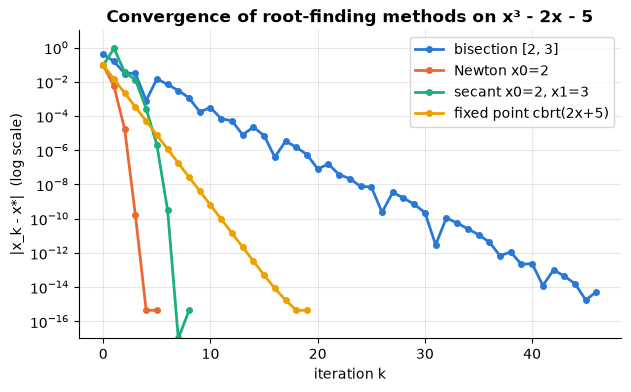

Newton iterates (watch the correct digits double):
  x_0 = 2.0000000000000000   error = 9.5e-02
  x_1 = 2.1000000000000001   error = 5.4e-03
  x_2 = 2.0945681211041851   error = 1.7e-05
  x_3 = 2.0945514816981992   error = 1.6e-10
  x_4 = 2.0945514815423265   error = 4.4e-16
  x_5 = 2.0945514815423265   error = 4.4e-16

SciPy: brentq -> 2.094551481542327 | newton -> 2.0945514815423265


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, xs in list(runs.items())[:4]:
    errs = np.maximum([abs(x - ROOT) for x in xs], 1e-17)
    ax.semilogy(range(len(errs)), errs, "o-", ms=4, label=name)
ax.set_xlabel("iteration k"); ax.set_ylabel("|x_k - x*|  (log scale)")
ax.set_title("Convergence of root-finding methods on x³ - 2x - 5")
ax.set_ylim(1e-17, 10); ax.legend(); plt.show()

print("Newton iterates (watch the correct digits double):")
for k, x in enumerate(runs["Newton x0=2"]):
    print(f"  x_{k} = {x:.16f}   error = {abs(x - ROOT):.1e}")
print("\nSciPy: brentq ->", optimize.brentq(f, 2, 3), "| newton ->", optimize.newton(f, 2.0, fprime=df))

**What just happened?**
- On the log-scale plot, **bisection** zig-zags but follows a straight downward trend (the *bracket* halves every step: linear, rate $1/2$, so 47 steps to go from width 1 to $10^{-14}$), and **fixed-point** iteration with $g(x) = \sqrt[3]{2x+5}$ is a steeper straight line (rate $|g'(x^*)| \approx 0.15$).
- **Newton** and **secant** curve downwards: quadratic and superlinear convergence. The estimated orders in the table are about 2.0 for Newton and 1.0 for the fixed-point iteration, as theory says. The secant estimate (about 1.8 against the theoretical 1.618) is rough, because only a handful of iterates exist before the error hits machine precision.
- With $g(x) = (x^3 - 5)/2$, $|g'(x^*)| \approx 6.6 > 1$, so the fixed-point iteration **diverges** even though $x^*$ is a fixed point.
- SciPy's `brentq` (bisection safeguarded with secant and inverse quadratic interpolation) is what you should use in practice when you can bracket the root.

**Failure cases of Newton's method.** Newton is fast only *near* a simple root.

In [5]:
cases = {
    "cycle: x³-2x+2 from x0=0": (lambda x: x**3 - 2 * x + 2, lambda x: 3 * x**2 - 2, 0.0),
    "divergence: cbrt(x) from x0=0.1": (np.cbrt, lambda x: (1 / 3) * abs(x) ** (-2 / 3), 0.1),
    "double root: (x-1)² from x0=2": (lambda x: (x - 1) ** 2, lambda x: 2 * (x - 1), 2.0),
}
for name, (fn, dfn, x0) in cases.items():
    xs = newton(fn, dfn, x0, max_iter=8)
    print(f"{name:34s}: " + ", ".join(f"{x:.4g}" for x in xs[:9]))
xs = newton(lambda x: (x - 1) ** 2, lambda x: 2 * (x - 1), 2.0, max_iter=30)
ratios = [abs(xs[k + 1] - 1) / abs(xs[k] - 1) for k in range(5)]
print("double root error ratios e_{k+1}/e_k:", np.round(ratios, 3), "-> only linear convergence (rate 1/2)")

cycle: x³-2x+2 from x0=0          : 0, 1, 0, 1, 0, 1, 0, 1, 0
divergence: cbrt(x) from x0=0.1   : 0.1, -0.2, 0.4, -0.8, 1.6, -3.2, 6.4, -12.8, 25.6
double root: (x-1)² from x0=2     : 2, 1.5, 1.25, 1.125, 1.062, 1.031, 1.016, 1.008, 1.004
double root error ratios e_{k+1}/e_k: [0.5 0.5 0.5 0.5 0.5] -> only linear convergence (rate 1/2)


**What just happened?**
- **Cycle:** for $x^3 - 2x + 2$ from $x_0 = 0$ the iterates bounce $0 \to 1 \to 0 \to 1$ forever.
- **Divergence:** for $f(x) = \sqrt[3]{x}$ the Newton step is $x_{k+1} = x_k - 3x_k = -2x_k$, so every step doubles the distance from the root.
- **Multiple root:** at a double root $f'(x^*) = 0$ and Newton drops to linear convergence with rate $1/2$.

Robust solvers therefore combine a *safe* method (bisection keeps a bracket) with a *fast* one (Newton or secant), switching to the safe step whenever the fast one misbehaves.

**Complexity.** Each iteration costs one evaluation of $f$ (bisection, secant) or of $f$ and $f'$ (Newton). Bisection needs $\lceil \log_2((b - a)/\text{tol}) \rceil$ iterations, which is 47 for an interval of length 1 and tolerance $10^{-14}$.

> ⚠️ **Common mistake.** Stopping when $|f(x_k)|$ is small. For a very flat function, $|f(x)|$ can be tiny far from the root; for a steep one, it can be large right next to it. Use a tolerance on the step $|x_{k+1} - x_k|$ (or on the bracket width) as well.

---
## 3. Interpolation

> **In plain English:** given a few known points, draw a smooth curve that passes through all of them, so you can estimate values in between.

**Definition.** Given $n+1$ points $(x_0, y_0), \dots, (x_n, y_n)$ with distinct $x_i$, there is **exactly one** polynomial $p$ of degree at most $n$ with $p(x_i) = y_i$ for all $i$: the **interpolating polynomial**. Two classic ways to write it:

- **Lagrange form:** $p(x) = \sum_i y_i \, \ell_i(x)$ with $\ell_i(x) = \prod_{j \ne i} \dfrac{x - x_j}{x_i - x_j}$. Each $\ell_i$ is 1 at $x_i$ and 0 at the other nodes.
- **Newton form:** $p(x) = c_0 + c_1(x - x_0) + c_2(x - x_0)(x - x_1) + \dots$ where the $c_k$ are **divided differences** $f[x_0, \dots, x_k]$, computed with the recursion $f[x_i, \dots, x_j] = \dfrac{f[x_{i+1}, \dots, x_j] - f[x_i, \dots, x_{j-1}]}{x_j - x_i}$. Adding a new point only adds one term.

**Worked example by hand** for the points $(0, 1), (1, 3), (2, 7)$:

| $x_i$ | $f[x_i]$ | $f[x_i, x_{i+1}]$ | $f[x_0, x_1, x_2]$ |
|---|---|---|---|
| 0 | 1 | $(3-1)/1 = 2$ | $(4-2)/(2-0) = 1$ |
| 1 | 3 | $(7-3)/1 = 4$ | |
| 2 | 7 | | |

So $p(x) = 1 + 2x + 1 \cdot x(x - 1) = x^2 + x + 1$. Check: $p(2) = 7$. ✓

**Error formula.** For a smooth $f$, $f(x) - p(x) = \dfrac{f^{(n+1)}(\xi)}{(n+1)!} \prod_{i=0}^n (x - x_i)$ for some $\xi$ in the interval. The product term is what goes wrong with equally spaced nodes.

In [6]:
def lagrange_eval(xn, yn, x):
    x = np.asarray(x, dtype=float); total = np.zeros_like(x)
    for i in range(len(xn)):
        li = np.ones_like(x)
        for j in range(len(xn)):
            if j != i:
                li *= (x - xn[j]) / (xn[i] - xn[j])      # basis polynomial l_i(x)
        total += yn[i] * li
    return total

def divided_differences(xn, yn):
    c = np.array(yn, dtype=float)
    for level in range(1, len(xn)):                      # build the table column by column, in place
        c[level:] = (c[level:] - c[level - 1:-1]) / (xn[level:] - xn[:-level])
    return c                                             # c[k] = f[x0, ..., xk]

def newton_eval(xn, c, x):
    x = np.asarray(x, dtype=float); p = np.full_like(x, c[-1])
    for k in range(len(c) - 2, -1, -1):                  # Horner-like nested evaluation
        p = p * (x - xn[k]) + c[k]
    return p

xn, yn = np.array([0., 1., 2.]), np.array([1., 3., 7.])
print("divided differences:", divided_differences(xn, yn), "-> p(x) = 1 + 2x + x(x-1) = x² + x + 1")
xt = np.linspace(-1, 3, 9)
assert np.allclose(newton_eval(xn, divided_differences(xn, yn), xt), xt**2 + xt + 1)
xr = np.sort(rng.uniform(-1, 1, 8)); yr = np.sin(3 * xr)
assert np.allclose(lagrange_eval(xr, yr, xt), newton_eval(xr, divided_differences(xr, yr), xt))
print("Lagrange and Newton forms agree (it is the same unique polynomial).")

divided differences: [1. 2. 1.] -> p(x) = 1 + 2x + x(x-1) = x² + x + 1
Lagrange and Newton forms agree (it is the same unique polynomial).


**Runge's phenomenon.** Interpolate $f(x) = \dfrac{1}{1 + 25x^2}$ on $[-1, 1]$. With **equally spaced** nodes, adding more points makes the error near the ends *worse*, growing without bound. The fix is to cluster nodes near the ends: **Chebyshev nodes** $x_k = \cos\!\left(\dfrac{(2k+1)\pi}{2(n+1)}\right)$, $k = 0, \dots, n$, minimise the product term $\max |\prod (x - x_i)|$, and the interpolant then converges for any smooth $f$.

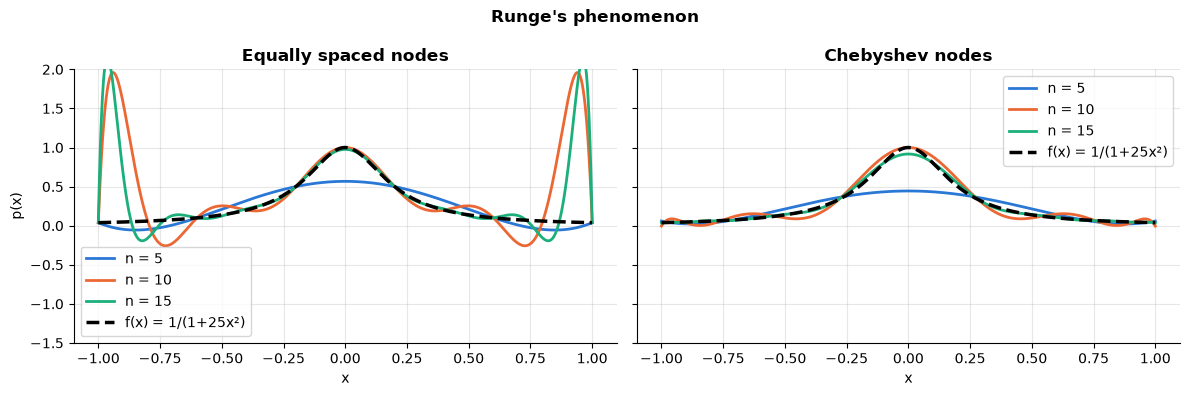

,degree n,"max error, equispaced","max error, Chebyshev"
0,5,0.433,0.556
1,10,1.92,0.109
2,15,2.11,0.0831
3,20,59.8,0.0153


In [7]:
runge = lambda x: 1 / (1 + 25 * x**2)
xx = np.linspace(-1, 1, 2001)
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for n in [5, 10, 15, 20]:
    equi = np.linspace(-1, 1, n + 1)
    cheb = np.cos((2 * np.arange(n + 1) + 1) * np.pi / (2 * (n + 1)))
    p_equi = newton_eval(equi, divided_differences(equi, runge(equi)), xx)
    p_cheb = newton_eval(cheb, divided_differences(cheb, runge(cheb)), xx)
    rows.append({"degree n": n, "max error, equispaced": np.abs(p_equi - runge(xx)).max(),
                 "max error, Chebyshev": np.abs(p_cheb - runge(xx)).max()})
    if n in (5, 10, 15):
        axes[0].plot(xx, p_equi, label=f"n = {n}"); axes[1].plot(xx, p_cheb, label=f"n = {n}")
for ax, title in zip(axes, ["Equally spaced nodes", "Chebyshev nodes"]):
    ax.plot(xx, runge(xx), "k--", lw=2.5, label="f(x) = 1/(1+25x²)")
    ax.set_ylim(-1.5, 2); ax.set_title(title); ax.set_xlabel("x"); ax.legend()
axes[0].set_ylabel("p(x)")
plt.suptitle("Runge's phenomenon", fontweight="bold"); plt.tight_layout(); plt.show()
pd.DataFrame(rows).style.format({"max error, equispaced": "{:.3g}", "max error, Chebyshev": "{:.3g}"})

**What just happened?** With equally spaced nodes the maximum error *grows* with the degree (from about 0.4 at $n = 5$ to about 60 at $n = 20$: the wild oscillations at the ends of the left plot), whereas with Chebyshev nodes it *shrinks* steadily (to about 0.015 at $n = 20$). At degree 5 both are poor: too few points to follow the sharp peak. High-degree polynomial interpolation on equally spaced data is a bad idea.

**Cubic splines: the practical answer.** Instead of one high-degree polynomial, use a separate **cubic** on each interval $[x_i, x_{i+1}]$, glued so that the value, slope and curvature (first and second derivatives) are continuous at every node. A **natural** spline also sets the second derivative to zero at both ends.

Writing $M_i = s''(x_i)$ and $h_i = x_{i+1} - x_i$, continuity of $s'$ gives one equation per interior node:

$$h_{i-1} M_{i-1} + 2(h_{i-1} + h_i) M_i + h_i M_{i+1} = 6\left(\frac{y_{i+1} - y_i}{h_i} - \frac{y_i - y_{i-1}}{h_{i-1}}\right),$$

a **tridiagonal** linear system, solved in $O(n)$ with the **Thomas algorithm** (Gaussian elimination that skips all the zeros).

In [8]:
def thomas(a, b, c, d):
    """Solve a tridiagonal system: a = sub-diagonal, b = diagonal, c = super-diagonal. O(n)."""
    n = len(b); cp, dp = np.zeros(n), np.zeros(n)
    cp[0], dp[0] = c[0] / b[0], d[0] / b[0]
    for i in range(1, n):                                    # forward elimination
        m = b[i] - a[i] * cp[i - 1]
        cp[i] = c[i] / m if i < n - 1 else 0.0
        dp[i] = (d[i] - a[i] * dp[i - 1]) / m
    x = np.zeros(n); x[-1] = dp[-1]
    for i in range(n - 2, -1, -1):                           # back substitution
        x[i] = dp[i] - cp[i] * x[i + 1]
    return x

def natural_cubic_spline(xn, yn):
    """Return a function s(x): the natural cubic spline through (xn, yn)."""
    h = np.diff(xn); n = len(xn)
    rhs = 6 * (np.diff(yn[1:]) / h[1:] - np.diff(yn[:-1]) / h[:-1])
    M = np.zeros(n)                                          # second derivatives; M_0 = M_{n-1} = 0
    if n > 2:
        M[1:-1] = thomas(np.r_[0, h[1:-1]], 2 * (h[:-1] + h[1:]), np.r_[h[1:-1], 0], rhs)
    def s(x):
        x = np.asarray(x, dtype=float)
        i = np.clip(np.searchsorted(xn, x) - 1, 0, n - 2)    # which interval each x falls in
        t1, t2 = xn[i + 1] - x, x - xn[i]
        return (M[i] * t1**3 + M[i + 1] * t2**3) / (6 * h[i]) \
             + (yn[i] / h[i] - M[i] * h[i] / 6) * t1 + (yn[i + 1] / h[i] - M[i + 1] * h[i] / 6) * t2
    return s

for n in [10, 20, 40]:
    xs_n = np.linspace(-1, 1, n + 1)
    s = natural_cubic_spline(xs_n, runge(xs_n))
    ref = interpolate.CubicSpline(xs_n, runge(xs_n), bc_type="natural")
    assert np.allclose(s(xx), ref(xx), atol=1e-12)
    print(f"{n + 1:3d} equally spaced points: spline max error = {np.abs(s(xx) - runge(xx)).max():.2e}"
          "  (matches scipy.interpolate.CubicSpline)")

 11 equally spaced points: spline max error = 2.20e-02  (matches scipy.interpolate.CubicSpline)
 21 equally spaced points: spline max error = 3.18e-03  (matches scipy.interpolate.CubicSpline)
 41 equally spaced points: spline max error = 2.78e-04  (matches scipy.interpolate.CubicSpline)


**What just happened?** On the *same* equally spaced points that ruined polynomial interpolation, the spline's error steadily decreases as points are added, and our from-scratch spline agrees with SciPy's to $10^{-12}$. For a cubic spline the error behaves like $O(h^4)$ away from the ends; with natural end conditions the accuracy near the ends is lower ($O(h^2)$) unless the true function also has zero curvature there.

**Complexity.** Building the Newton divided-difference table is $O(n^2)$; evaluating either polynomial form is $O(n)$ per point (Lagrange as written is $O(n^2)$; the *barycentric* Lagrange formula brings it to $O(n)$). A natural cubic spline costs $O(n)$ to build (one tridiagonal solve) and $O(\log n)$ per evaluation (binary search for the interval).

> 🎓 **Exam / interview tip.** Know the uniqueness theorem (one polynomial of degree $\le n$ through $n+1$ points), the divided-difference table, and the three fixes for Runge: Chebyshev nodes, piecewise (spline) interpolation, or least-squares fitting of a lower degree.

---
## 4. Numerical differentiation

> **In plain English:** estimate a slope by measuring the function at two nearby points, and choose the gap carefully, because both a large and a tiny gap give wrong answers.

From the Taylor series $f(x + h) = f(x) + h f'(x) + \tfrac{h^2}{2} f''(x) + \tfrac{h^3}{6} f^{(3)}(x) + \dots$:

| Formula | Expression | Truncation error | Best $h$ in float64 | Best error |
|---|---|---|---|---|
| **Forward difference** | $\dfrac{f(x+h) - f(x)}{h}$ | $\tfrac{h}{2} \lvert f''\rvert = O(h)$ | $\approx \sqrt{\varepsilon_{\text{mach}}} \approx 10^{-8}$ | $\approx 10^{-8}$ to $10^{-9}$ |
| **Central difference** | $\dfrac{f(x+h) - f(x-h)}{2h}$ | $\tfrac{h^2}{6} \lvert f^{(3)}\rvert = O(h^2)$ | $\approx \varepsilon_{\text{mach}}^{1/3} \approx 6 \times 10^{-6}$ | $\approx 10^{-11}$ |
| **Complex step** | $\dfrac{\operatorname{Im} f(x + ih)}{h}$ | $O(h^2)$, *no subtraction* | any tiny $h$, e.g. $10^{-20}$ | $\approx 10^{-16}$ |

**The trade-off.** The numerator is a difference of two nearly equal numbers, each with round-off error about $\varepsilon_{\text{mach}} |f|$. Dividing by $h$ amplifies that to about $\varepsilon_{\text{mach}} |f| / h$. Total error $\approx \tfrac{h}{2}|f''| + \tfrac{2\varepsilon |f|}{h}$ for the forward difference, which is smallest at $h \approx 2\sqrt{\varepsilon |f| / |f''|}$. Too large an $h$: truncation dominates. Too small: round-off dominates.

The **complex-step** trick (for real-analytic $f$ implemented with complex-safe operations) avoids the subtraction entirely: $f(x + ih) = f(x) + ih f'(x) - \tfrac{h^2}{2} f''(x) + \dots$, so the imaginary part divided by $h$ is $f'(x) + O(h^2)$.

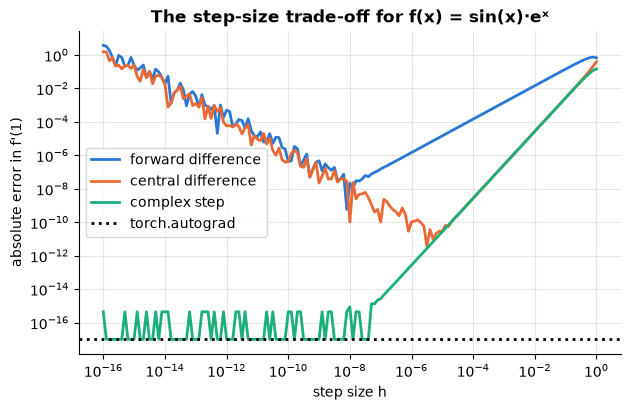

forward : best h = 7.9e-09, best error = 5.9e-10
central : best h = 3.2e-06, best error = 3.9e-12
complex step at h=1e-20: error = 0.0e+00
torch.autograd: error = 0.0e+00


In [9]:
import torch
torch.set_num_threads(2)

fx = lambda x: np.sin(x) * np.exp(x)                  # works for real AND complex x
dfx_true = lambda x: (np.cos(x) + np.sin(x)) * np.exp(x)
x0, exact = 1.0, dfx_true(1.0)

hs = np.logspace(-16, 0, 161)
err_fwd = np.abs((fx(x0 + hs) - fx(x0)) / hs - exact)
err_ctr = np.abs((fx(x0 + hs) - fx(x0 - hs)) / (2 * hs) - exact)
err_cs = np.abs(np.imag(fx(x0 + 1j * hs)) / hs - exact)

xt = torch.tensor(x0, dtype=torch.float64, requires_grad=True)
(torch.sin(xt) * torch.exp(xt)).backward()             # reverse-mode automatic differentiation
err_ad = abs(xt.grad.item() - exact)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(hs, np.maximum(err_fwd, 1e-17), label="forward difference")
ax.loglog(hs, np.maximum(err_ctr, 1e-17), label="central difference")
ax.loglog(hs, np.maximum(err_cs, 1e-17), label="complex step")
ax.axhline(max(err_ad, 1e-17), color="k", ls=":", label="torch.autograd")
ax.set_xlabel("step size h"); ax.set_ylabel("absolute error in f'(1)")
ax.set_title("The step-size trade-off for f(x) = sin(x)·eˣ"); ax.legend(); plt.show()

for name, err in [("forward", err_fwd), ("central", err_ctr)]:
    k = np.nanargmin(err)
    print(f"{name:8s}: best h = {hs[k]:.1e}, best error = {err[k]:.1e}")
print(f"complex step at h=1e-20: error = {abs(np.imag(fx(x0 + 1e-20j)) / 1e-20 - exact):.1e}")
print(f"torch.autograd: error = {err_ad:.1e}")

**What just happened?** Each curve is V-shaped: on the right, truncation error falls as $h$ shrinks (slope 1 for forward, slope 2 for central on the log-log plot); on the left, round-off error rises like $1/h$. The printed best step sizes are close to the theoretical $10^{-8}$ (forward) and $10^{-5}$ (central), and the best errors are about $6 \times 10^{-10}$ and $4 \times 10^{-12}$ (the very lowest point of a noisy curve is a little luckier than the typical error at that $h$). The complex step and automatic differentiation are both accurate to about machine precision, because neither subtracts nearly equal numbers.

**Why ML uses autodiff instead.** For a model with $n$ parameters, finite differences need $n + 1$ (forward) or $2n$ (central) evaluations of the loss to get a gradient, and are only accurate to about 5 to 10 digits. Reverse-mode autodiff gets the exact gradient (up to round-off) for a small constant multiple of *one* evaluation. Finite differences remain the standard way to **test** an autodiff implementation (gradient checking), which [`11_matrix_calculus_and_autodiff_from_scratch.ipynb`](11_matrix_calculus_and_autodiff_from_scratch.ipynb) builds from scratch.

> ⚠️ **Common mistake.** Using `h = 1e-15` "to be precise". The plot shows that the error is then around $10^{-1}$ or worse. In float32 (most deep-learning code) $\varepsilon_{\text{mach}} \approx 1.2 \times 10^{-7}$, so the best central-difference step is about $5 \times 10^{-3}$ and gradient checks should be done in float64.

---
## 5. Numerical integration (quadrature)

> **In plain English:** to find an area under a curve, cut it into thin slices whose areas are easy, and add them up; smarter slicing gets more accuracy from fewer function evaluations.

**Newton–Cotes rules** on $n$ equal sub-intervals of width $h = (b - a)/n$:
- **Composite trapezoid:** $\int_a^b f \approx h\left[\tfrac12 f_0 + f_1 + \dots + f_{n-1} + \tfrac12 f_n\right]$. Error $-\tfrac{(b-a) h^2}{12} f''(\xi) = O(h^2)$.
- **Composite Simpson** ($n$ even): $\tfrac{h}{3}\left[f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + 4f_{n-1} + f_n\right]$, which fits a parabola through each pair of slices. Error $-\tfrac{(b-a) h^4}{180} f^{(4)}(\xi) = O(h^4)$.

**Gauss–Legendre quadrature** chooses *both* the nodes $x_i$ and the weights $w_i$ in $\int_{-1}^1 f \approx \sum_{i=1}^n w_i f(x_i)$ so that the rule is exact for every polynomial of degree up to $2n - 1$, the maximum possible with $n$ points. The nodes are the roots of the Legendre polynomial $P_n$. A neat way to compute them is the **Golub–Welsch** algorithm: they are the eigenvalues of a symmetric tridiagonal matrix with off-diagonal entries $\beta_k = k / \sqrt{4k^2 - 1}$, and each weight is $2 v_{1}^2$, where $v_1$ is the first component of the corresponding unit eigenvector.

Test problem: $I = \int_0^2 e^{-x^2}\,dx = \tfrac{\sqrt\pi}{2}\operatorname{erf}(2) \approx 0.882081$.

Golub-Welsch nodes and weights match numpy.polynomial.legendre.leggauss


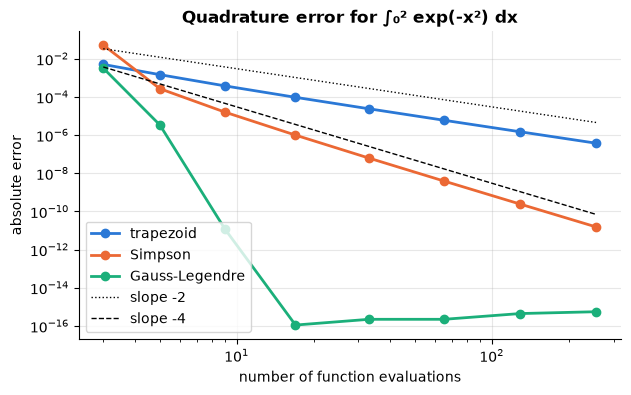

,trapezoid,Simpson,Gauss-Legendre
evaluations,,,
3,5.04e-03,5.21e-02,3.22e-03
5,1.46e-03,2.69e-04,3.37e-06
9,3.78e-04,1.59e-05,1.17e-11
17,9.51e-05,9.94e-07,1.11e-16
33,2.38e-05,6.21e-08,2.22e-16
65,5.96e-06,3.88e-09,2.22e-16
129,1.49e-06,2.43e-10,4.44e-16
257,3.73e-07,1.52e-11,5.55e-16


In [10]:
def trapezoid(f, a, b, n):
    x = np.linspace(a, b, n + 1); y = f(x)
    return (b - a) / n * (y[0] / 2 + y[1:-1].sum() + y[-1] / 2)

def simpson(f, a, b, n):
    assert n % 2 == 0, "Simpson needs an even number of intervals"
    x = np.linspace(a, b, n + 1); y = f(x); h = (b - a) / n
    return h / 3 * (y[0] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum() + y[-1])

def gauss_legendre_nodes(n):
    """Golub-Welsch: nodes and weights of n-point Gauss-Legendre on [-1, 1]."""
    k = np.arange(1, n)
    beta = k / np.sqrt(4 * k**2 - 1)
    J = np.diag(beta, 1) + np.diag(beta, -1)              # symmetric tridiagonal Jacobi matrix
    nodes, vecs = np.linalg.eigh(J)
    return nodes, 2 * vecs[0, :] ** 2

def gauss_legendre(f, a, b, n):
    t, w = gauss_legendre_nodes(n)
    x = (b - a) / 2 * t + (a + b) / 2                     # map [-1, 1] to [a, b]
    return (b - a) / 2 * np.sum(w * f(x))

for n in [2, 5, 10, 20]:
    t, w = gauss_legendre_nodes(n); t_ref, w_ref = np.polynomial.legendre.leggauss(n)
    assert np.allclose(t, t_ref) and np.allclose(w, w_ref)
print("Golub-Welsch nodes and weights match numpy.polynomial.legendre.leggauss")

g = lambda x: np.exp(-x**2)
I_true = math.sqrt(math.pi) / 2 * math.erf(2)
evals = np.array([3, 5, 9, 17, 33, 65, 129, 257])           # function evaluations used
errs = {"trapezoid": [abs(trapezoid(g, 0, 2, m - 1) - I_true) for m in evals],
        "Simpson": [abs(simpson(g, 0, 2, m - 1) - I_true) for m in evals],
        "Gauss-Legendre": [abs(gauss_legendre(g, 0, 2, m) - I_true) for m in evals]}
fig, ax = plt.subplots(figsize=(7, 4))
for name, e in errs.items():
    ax.loglog(evals, np.maximum(e, 1e-17), "o-", label=name)
ax.loglog(evals, 0.3 * evals**-2.0, "k:", lw=1, label="slope -2")
ax.loglog(evals, 0.3 * evals**-4.0, "k--", lw=1, label="slope -4")
ax.set_xlabel("number of function evaluations"); ax.set_ylabel("absolute error")
ax.set_title("Quadrature error for ∫₀² exp(-x²) dx"); ax.legend(); plt.show()
pd.DataFrame(errs, index=evals).rename_axis("evaluations").style.format("{:.2e}")

**What just happened?** On the log-log plot the trapezoid error falls with slope $-2$ and Simpson with slope $-4$, as the error formulas predict (halving $h$ divides the error by about 4 and 16). Gauss–Legendre drops much faster still and reaches machine precision with only about 17 evaluations: for smooth (analytic) functions its error decreases **exponentially** in $n$.

**Adaptive quadrature.** Real integrands are often smooth in most places and sharp in a few. **Adaptive Simpson** estimates the error on each interval by comparing one Simpson step with two half-steps, and only subdivides where the estimate is too large. `scipy.integrate.quad` (based on QUADPACK's Gauss–Kronrod rules) does the same thing more cleverly and also returns an error estimate.

In [11]:
def adaptive_simpson(f, a, b, tol=1e-10):
    calls = [0]
    def F(x):
        calls[0] += 1; return f(x)
    def simpson_step(a, fa, b, fb):
        m = (a + b) / 2; fm = F(m)
        return m, fm, (b - a) / 6 * (fa + 4 * fm + fb)
    def recurse(a, fa, b, fb, m, fm, whole, tol, depth):
        lm, flm, left = simpson_step(a, fa, m, fm)
        rm, frm, right = simpson_step(m, fm, b, fb)
        if depth > 50 or abs(left + right - whole) <= 15 * tol:        # error estimate (Richardson)
            return left + right + (left + right - whole) / 15
        return recurse(a, fa, m, fm, lm, flm, left, tol / 2, depth + 1) + \
               recurse(m, fm, b, fb, rm, frm, right, tol / 2, depth + 1)
    fa, fb = F(a), F(b)
    m, fm, whole = simpson_step(a, fa, b, fb)
    return recurse(a, fa, b, fb, m, fm, whole, tol, 0), calls[0]

tests = {
    "sharp peak 1/((x-0.3)² + 1e-6)": (lambda x: 1 / ((x - 0.3) ** 2 + 1e-6),
                                        (math.atan(0.7 / 1e-3) + math.atan(0.3 / 1e-3)) / 1e-3),
    "sqrt(x) (infinite slope at 0)": (np.sqrt, 2 / 3),
}
rows = []
for name, (fn, I_exact) in tests.items():
    val, calls = adaptive_simpson(fn, 0.0, 1.0, tol=1e-6 * abs(I_exact))     # relative tolerance 1e-6
    uniform = simpson(fn, 0, 1, calls - 1 if (calls - 1) % 2 == 0 else calls)  # same budget, equal spacing
    q, q_err, info = integrate.quad(fn, 0, 1, full_output=True)[:3]
    rows.append({"integrand": name, "evaluations (adaptive)": calls,
                 "rel. error adaptive Simpson": abs(val - I_exact) / I_exact,
                 "rel. error uniform Simpson, same budget": abs(uniform - I_exact) / I_exact,
                 "quad evaluations": info["neval"], "rel. error quad": abs(q - I_exact) / I_exact})
pd.DataFrame(rows).style.format({c: "{:.1e}" for c in rows[0] if "error" in c})

,integrand,evaluations (adaptive),rel. error adaptive Simpson,"rel. error uniform Simpson, same budget",quad evaluations,rel. error quad
0,sharp peak 1/((x-0.3)² + 1e-6),653,3.5e-08,5.2e-02,525,5.2e-15
1,sqrt(x) (infinite slope at 0),113,2.2e-08,1.0e-04,231,3.3e-16


**What just happened?** For the same number of function evaluations, adaptive Simpson is thousands to millions of times more accurate than uniform Simpson, because it spends its evaluations near the peak and near the infinite slope of $\sqrt{x}$ at 0, where the smoothness assumptions of Simpson's error formula break down. `quad` reaches about machine precision with a few hundred evaluations, and also returns an error estimate you can check.

**Complexity.** All of these rules cost one function evaluation per node, so cost is measured in *evaluations*. To reach error $\epsilon$: trapezoid needs $O(\epsilon^{-1/2})$ evaluations, Simpson $O(\epsilon^{-1/4})$, and Gauss–Legendre on analytic functions only $O(\log(1/\epsilon))$.

> 🎓 **Exam / interview tip.** "Simpson's rule is exact for cubics" (not just quadratics): the error term involves $f^{(4)}$, which is zero for a cubic. Likewise an $n$-point Gauss rule is exact up to degree $2n - 1$, so 2 points integrate any cubic exactly.

---
## 6. Monte Carlo integration

> **In plain English:** estimate an average (an integral) by sampling random points and averaging, which is slow to become precise but works the same in 2 or 2,000 dimensions.

**Idea.** $\int_a^b f(x)\,dx = (b - a)\,\mathbb{E}[f(U)]$ for $U$ uniform on $[a, b]$. So draw $n$ random points and average:

$$\hat I_n = \frac{b - a}{n} \sum_{i=1}^n f(U_i), \qquad \text{standard error} = \frac{(b - a)\,\sigma_f}{\sqrt n}.$$

By the central limit theorem the error shrinks like $1/\sqrt n$, **whatever the dimension**. That is terrible in one dimension (to gain one more correct digit you need 100 times more samples) but unbeatable in high dimensions, where a grid with $m$ points per axis needs $m^d$ points (the **curse of dimensionality**).

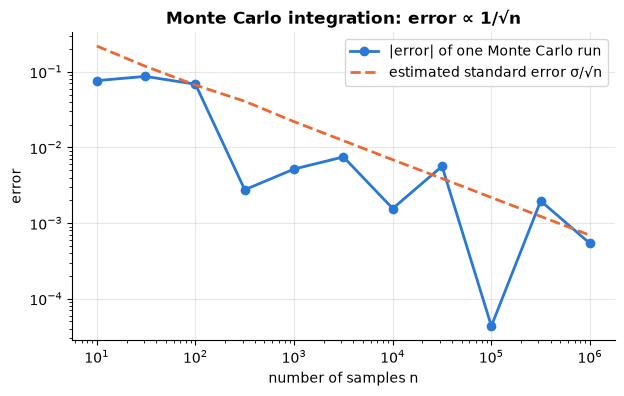

n = 1,000,000: estimate = 0.881544 ± 0.001350 (95% CI), true = 0.882081
8-dimensional integral: Monte Carlo 0.3748 ± 0.0108 (95% CI) vs exact 0.3665 with 200,000 samples;
  a 10-point-per-axis grid would need 100,000,000 evaluations


In [12]:
ns = np.logspace(1, 6, 11).astype(int)
mc_err, mc_se = [], []
for n in ns:
    u = rng.uniform(0, 2, size=n)
    vals = 2 * g(u)
    mc_err.append(abs(vals.mean() - I_true)); mc_se.append(vals.std(ddof=1) / math.sqrt(n))
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ns, mc_err, "o-", label="|error| of one Monte Carlo run")
ax.loglog(ns, mc_se, "--", label="estimated standard error σ/√n")
ax.set_xlabel("number of samples n"); ax.set_ylabel("error"); ax.legend()
ax.set_title("Monte Carlo integration: error ∝ 1/√n"); plt.show()
print(f"n = {ns[-1]:,}: estimate = {vals.mean():.6f} ± {1.96 * mc_se[-1]:.6f} (95% CI), true = {I_true:.6f}")

# The same idea in 8 dimensions: E[exp(-|X|^2)] for X uniform on [0,2]^8 = (I_true/2)^8
d8, n8 = 8, 200_000
X = rng.uniform(0, 2, size=(n8, d8))
vals8 = np.exp(-(X**2).sum(axis=1)) * 2**d8
est, se = vals8.mean(), vals8.std(ddof=1) / math.sqrt(n8)
print(f"8-dimensional integral: Monte Carlo {est:.4f} ± {1.96 * se:.4f} (95% CI) vs exact {I_true**d8:.4f}"
      f" with {n8:,} samples;\n  a 10-point-per-axis grid would need {10**d8:,} evaluations")

**What just happened?** The error of a single run wobbles (it is random) but follows the $1/\sqrt n$ line; going from $10^2$ to $10^6$ samples gains only about 2 digits. In 8 dimensions, Monte Carlo gets within a few percent of the right answer with a fifth of a million samples (the confidence interval tells you how far to trust it; this integrand has a large variance because most of its mass sits in one corner of the cube), while a modest grid would already need $10^8$ evaluations.

Variance-reduction tricks (importance sampling, control variates, antithetic variables, quasi-Monte Carlo with low-discrepancy sequences such as Sobol, available in `scipy.stats.qmc`) reduce the constant $\sigma_f$ or improve the rate.

---
## 7. Ordinary differential equations

> **In plain English:** if you know how fast something is changing right now, you can predict where it will be by taking many small steps forward in time, as long as the steps are small enough to stay stable.

An **initial value problem (IVP)** is $y'(t) = f(t, y)$, $y(t_0) = y_0$. Most ODEs have no closed-form solution, so we march forward with step $h$:

| Method | Update | Global error | Evaluations of $f$ per step |
|---|---|---|---|
| **Forward (explicit) Euler** | $y_{n+1} = y_n + h f(t_n, y_n)$ | $O(h)$ | 1 |
| **Classical Runge–Kutta (RK4)** | weighted average of 4 slopes $k_1, \dots, k_4$ | $O(h^4)$ | 4 |
| **Backward (implicit) Euler** | $y_{n+1} = y_n + h f(t_{n+1}, y_{n+1})$, solve for $y_{n+1}$ | $O(h)$ | 1 + an equation solve |

RK4: $k_1 = f(t_n, y_n)$, $k_2 = f(t_n + \tfrac h2, y_n + \tfrac h2 k_1)$, $k_3 = f(t_n + \tfrac h2, y_n + \tfrac h2 k_2)$, $k_4 = f(t_n + h, y_n + h k_3)$, $y_{n+1} = y_n + \tfrac h6 (k_1 + 2k_2 + 2k_3 + k_4)$.

**Worked example by hand.** $y' = y$, $y(0) = 1$, $h = 0.5$, forward Euler: $y_1 = 1 + 0.5 \cdot 1 = 1.5$, $y_2 = 1.5 + 0.5 \cdot 1.5 = 2.25$. The true $y(1) = e \approx 2.718$, so the error is 0.47. Halving $h$ roughly halves the error (first order).

Euler, h = 0.5: [1.   1.5  2.25] (matches the hand calculation)


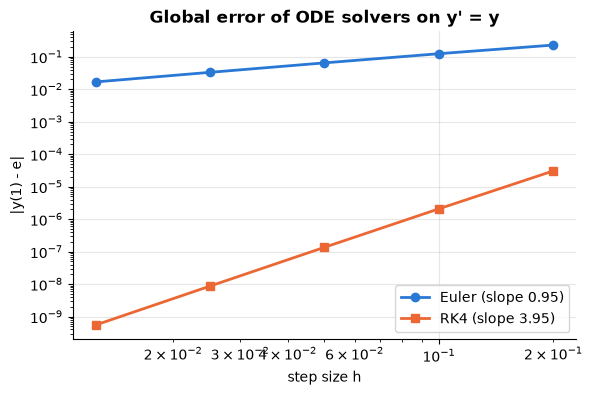

In [13]:
def euler(f, t0, y0, t_end, h):
    n = int(round((t_end - t0) / h)); t, y = t0, np.array(y0, dtype=float)
    ts, ys = [t], [y.copy()]
    for _ in range(n):
        y = y + h * f(t, y); t += h                     # follow the current slope for one step
        ts.append(t); ys.append(y.copy())
    return np.array(ts), np.array(ys)

def rk4(f, t0, y0, t_end, h):
    n = int(round((t_end - t0) / h)); t, y = t0, np.array(y0, dtype=float)
    ts, ys = [t], [y.copy()]
    for _ in range(n):
        k1 = f(t, y)
        k2 = f(t + h / 2, y + h / 2 * k1)
        k3 = f(t + h / 2, y + h / 2 * k2)
        k4 = f(t + h, y + h * k3)
        y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4); t += h
        ts.append(t); ys.append(y.copy())
    return np.array(ts), np.array(ys)

grow = lambda t, y: y
print("Euler, h = 0.5:", euler(grow, 0, [1.0], 1, 0.5)[1].ravel(), "(matches the hand calculation)")
hs_ode = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])
e_eu = [abs(euler(grow, 0, [1.0], 1, h)[1][-1, 0] - math.e) for h in hs_ode]
e_rk = [abs(rk4(grow, 0, [1.0], 1, h)[1][-1, 0] - math.e) for h in hs_ode]
p_eu = np.polyfit(np.log(hs_ode), np.log(e_eu), 1)[0]
p_rk = np.polyfit(np.log(hs_ode), np.log(e_rk), 1)[0]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(hs_ode, e_eu, "o-", label=f"Euler (slope {p_eu:.2f})")
ax.loglog(hs_ode, e_rk, "s-", label=f"RK4 (slope {p_rk:.2f})")
ax.set_xlabel("step size h"); ax.set_ylabel("|y(1) - e|"); ax.set_title("Global error of ODE solvers on y' = y")
ax.legend(); plt.show()

**What just happened?** The fitted slopes are about 1 for Euler and about 4 for RK4, confirming their orders. With $h = 0.0125$ (80 steps), RK4 is accurate to about $10^{-9}$, while Euler is still wrong in the second decimal place.

**Stability.** Apply forward Euler to the test equation $y' = \lambda y$ with $\lambda < 0$ (true solution decays): $y_{n+1} = (1 + h\lambda) y_n$. The numerical solution decays only if $|1 + h\lambda| \le 1$, that is $h \le 2/|\lambda|$. Above that limit it **oscillates and explodes**, however accurate each individual step looked.

An ODE is **stiff** when it contains a very fast decaying component (large $|\lambda|$) alongside the slow behaviour you care about. Explicit methods are then forced to take tiny steps for *stability*, not accuracy. **Implicit** methods such as backward Euler, Radau or BDF are stable for any step size on decaying problems ($y_{n+1} = y_n / (1 - h\lambda)$ always shrinks), at the cost of solving an equation each step.

Our stiff test problem: $y' = -1000\,(y - \cos t) - \sin t$, $y(0) = 1$, whose exact solution is simply $y = \cos t$. Any deviation from $\cos t$ is pulled back with rate 1000.

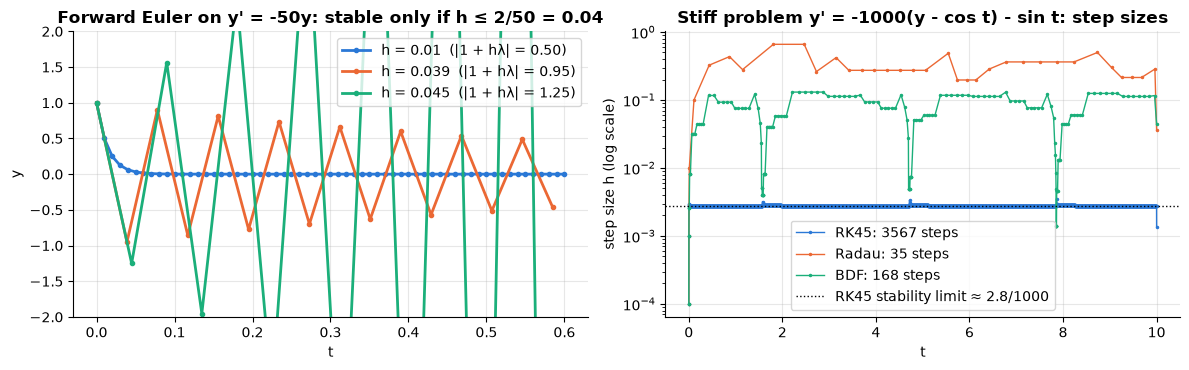

forward Euler with h = 0.01 (|1 + hλ| = 9): |y| after 50 steps = 2.58e+42  -> exploded


,method,steps,f evaluations,max error vs cos t,seconds
0,RK45,3567,21428,7.0e-07,0.358
1,Radau,35,292,2.0e-06,0.021
2,BDF,168,438,2.6e-07,0.054
3,"backward Euler (scratch), h=0.1",100,100,5.0e-05,nan


In [14]:
lam = -50.0
decay = lambda t, y: lam * y
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for h in [0.01, 0.039, 0.045]:
    ts, ys = euler(decay, 0, [1.0], 0.6, h)
    axes[0].plot(ts, ys[:, 0], "o-", ms=3, label=f"h = {h}  (|1 + hλ| = {abs(1 + h * lam):.2f})")
axes[0].set_ylim(-2, 2); axes[0].set_xlabel("t"); axes[0].set_ylabel("y")
axes[0].set_title("Forward Euler on y' = -50y: stable only if h ≤ 2/50 = 0.04"); axes[0].legend()

stiff = lambda t, y: -1000 * (y - np.cos(t)) - np.sin(t)
rows = []
for method in ["RK45", "Radau", "BDF"]:
    t0 = time.perf_counter()
    sol = integrate.solve_ivp(stiff, (0, 10), [1.0], method=method, rtol=1e-6, atol=1e-9)
    rows.append({"method": method, "steps": len(sol.t) - 1, "f evaluations": sol.nfev,
                 "max error vs cos t": np.abs(sol.y[0] - np.cos(sol.t)).max(),
                 "seconds": time.perf_counter() - t0})
    axes[1].semilogy(sol.t[1:], np.diff(sol.t), ".-", ms=3, lw=1, label=f"{method}: {len(sol.t) - 1} steps")

# Backward Euler from scratch: y_{n+1} = y_n + h(-1000(y_{n+1} - cos t_{n+1}) - sin t_{n+1}), solved exactly
h = 0.1; ts = np.arange(0, 10 + h / 2, h); y = [1.0]
for t_next in ts[1:]:
    y.append((y[-1] + h * (1000 * np.cos(t_next) - np.sin(t_next))) / (1 + 1000 * h))
rows.append({"method": "backward Euler (scratch), h=0.1", "steps": len(ts) - 1, "f evaluations": len(ts) - 1,
             "max error vs cos t": np.abs(np.array(y) - np.cos(ts)).max(), "seconds": float("nan")})
_, y_fe = euler(stiff, 0, [1.0], 0.5, 0.01)
axes[1].axhline(2.8 / 1000, color="k", ls=":", lw=1, label="RK45 stability limit ≈ 2.8/1000")
axes[1].set_xlabel("t"); axes[1].set_ylabel("step size h (log scale)")
axes[1].set_title("Stiff problem y' = -1000(y - cos t) - sin t: step sizes"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"forward Euler with h = 0.01 (|1 + hλ| = 9): |y| after 50 steps = {abs(y_fe[-1, 0]):.2e}  -> exploded")
pd.DataFrame(rows).style.format({"max error vs cos t": "{:.1e}", "seconds": "{:.3f}"})

**What just happened?**
- **Left:** with $h = 0.01$ and $h = 0.039$ forward Euler decays (the second one oscillates, because $1 + h\lambda < 0$); with $h = 0.045$, just over the limit $2/50 = 0.04$, it grows without bound.
- **Right and table:** on the stiff problem, the explicit adaptive solver RK45 is forced into thousands of tiny steps, its step size pinned near its stability limit (about $2.8/1000$ for this $\lambda = -1000$), even though the solution is just a smooth $\cos t$. The implicit solvers Radau and BDF need only a small fraction of the steps and function evaluations for comparable accuracy. Our from-scratch backward Euler is stable with $h = 0.1$, a step 100 times larger than forward Euler's stability limit of $2/1000$, while forward Euler with $h = 0.01$ explodes.

**Complexity.** An explicit method costs a fixed number of $f$ evaluations per step ($s$ for an $s$-stage RK method). An implicit method also solves a (generally nonlinear) system per step, typically by Newton's method with an $O(d^3)$ linear solve for a $d$-dimensional system, which is worth it only when stiffness would otherwise force tiny steps.

> ⚠️ **Common mistake.** Reaching for `method="RK45"` (the `solve_ivp` default) on chemistry, circuit or control problems and concluding "the solver is slow". If the step count explodes, try `"Radau"`, `"BDF"` or `"LSODA"` (which switches automatically).

Neural ODEs ([`05_Deep_Learning/10_neural_ode.ipynb`](../05_Deep_Learning/10_neural_ode.ipynb)) put a neural network in place of $f$; exactly the same accuracy, stiffness and step-count issues decide their training cost.

---
## 8. Least-squares curve fitting

> **In plain English:** when data are noisy, do not force the curve through every point; choose the curve's settings that make the total squared miss as small as possible, then check what is left over.

Interpolation passes *through* every point; with noisy data that fits the noise. **Least squares** instead chooses the parameters $\theta$ of a model $y \approx m(x; \theta)$ to minimise

$$S(\theta) = \sum_i \big(y_i - m(x_i; \theta)\big)^2.$$

For a linear model this is a linear-algebra problem (next notebook). For a nonlinear model such as exponential decay $m(x) = a e^{-bx} + c$, `scipy.optimize.curve_fit` uses the Levenberg–Marquardt algorithm (a blend of Gauss–Newton and gradient descent) and returns the covariance matrix of the estimates, whose diagonal gives **standard errors**.

**Residual diagnostics.** After fitting, plot the residuals $r_i = y_i - m(x_i; \hat\theta)$. A good model leaves residuals that look like structureless noise around zero. A *pattern* (a curve, a funnel) means the model is wrong, however good $R^2$ looks.

   true  estimate  std. error  95% CI low  95% CI high
a   2.5    2.4911      0.0279      2.4364       2.5458
b   1.3    1.3252      0.0318      1.2629       1.3875
c   0.5    0.5070      0.0119      0.4836       0.5304

R² exponential model = 0.9939;  R² straight line = 0.7009


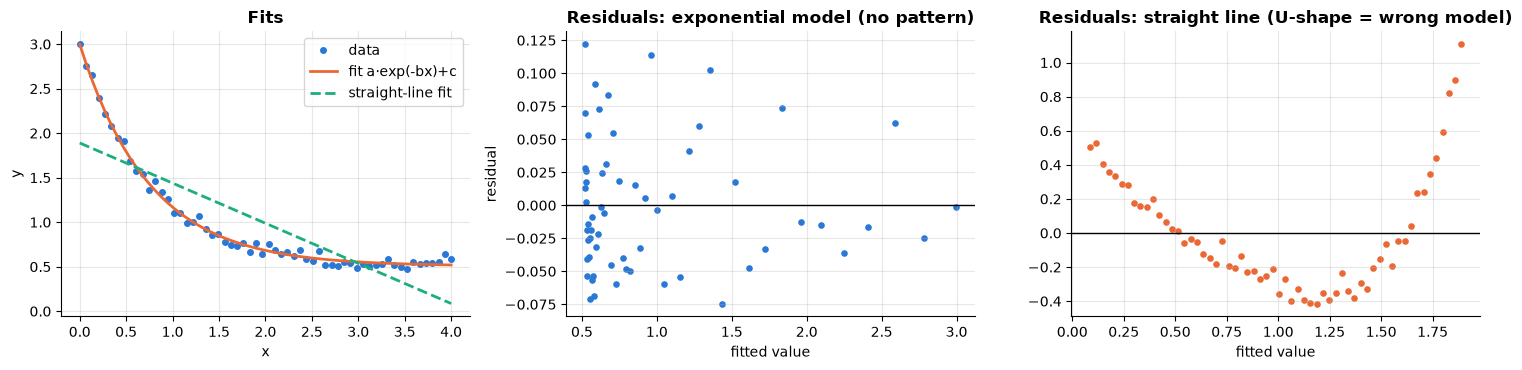

In [15]:
true_params = (2.5, 1.3, 0.5)
model = lambda x, a, b, c: a * np.exp(-b * x) + c
x_data = np.linspace(0, 4, 60)
y_data = model(x_data, *true_params) + rng.normal(0, 0.05, size=x_data.size)

popt, pcov = optimize.curve_fit(model, x_data, y_data, p0=(1, 1, 0))
perr = np.sqrt(np.diag(pcov))                                   # standard errors
lin = np.polyfit(x_data, y_data, 1)                             # a deliberately wrong (linear) model
res_exp = y_data - model(x_data, *popt)
res_lin = y_data - np.polyval(lin, x_data)
r2 = lambda r: 1 - (r**2).sum() / ((y_data - y_data.mean())**2).sum()
print(pd.DataFrame({"true": true_params, "estimate": popt, "std. error": perr,
                    "95% CI low": popt - 1.96 * perr, "95% CI high": popt + 1.96 * perr},
                   index=["a", "b", "c"]).round(4))
print(f"\nR² exponential model = {r2(res_exp):.4f};  R² straight line = {r2(res_lin):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(x_data, y_data, "o", ms=4, label="data")
axes[0].plot(x_data, model(x_data, *popt), label="fit a·exp(-bx)+c")
axes[0].plot(x_data, np.polyval(lin, x_data), "--", label="straight-line fit")
axes[0].set_title("Fits"); axes[0].set_xlabel("x"); axes[0].set_ylabel("y"); axes[0].legend()
axes[1].scatter(model(x_data, *popt), res_exp, s=14); axes[1].axhline(0, color="k", lw=1)
axes[1].set_title("Residuals: exponential model (no pattern)"); axes[1].set_xlabel("fitted value")
axes[1].set_ylabel("residual")
axes[2].scatter(np.polyval(lin, x_data), res_lin, s=14, color=PALETTE[1]); axes[2].axhline(0, color="k", lw=1)
axes[2].set_title("Residuals: straight line (U-shape = wrong model)"); axes[2].set_xlabel("fitted value")
plt.tight_layout(); plt.show()

**What just happened?** The fitted $a$, $b$, $c$ are close to the true values (2.5, 1.3, 0.5), and each 95% interval in the table contains the truth. The straight line still has a respectable-looking $R^2$, but its residual plot shows a clear U-shaped pattern: the model is systematically wrong, which $R^2$ alone hides.

> 🎓 **Exam / interview tip.** `curve_fit` needs a sensible starting guess `p0` for nonlinear models: Levenberg–Marquardt is a *local* method and can converge to a poor local minimum or fail to converge. Standard errors from `pcov` assume independent, equal-variance noise; if that is doubtful, use the bootstrap ([`04_statistics.ipynb`](04_statistics.ipynb)).

---
## 9. Summary table

> **In plain English:** one table to choose a method, and to remember how fast each one improves.

| Task | Method | Order / rate | Cost per step | Use when |
|---|---|---|---|---|
| Root | Bisection | linear, error halves | 1 $f$ | you can bracket the root and need a guarantee |
| Root | Newton | quadratic (simple root) | $f$ and $f'$ | good starting guess, derivative available |
| Root | Secant | order 1.618 | 1 $f$ | no derivative |
| Root | Brent (`brentq`) | superlinear and guaranteed | 1 $f$ | the default in practice |
| Interpolation | Polynomial (Newton form) | depends on node choice | $O(n^2)$ build | few points, or Chebyshev nodes |
| Interpolation | Cubic spline | $O(h^4)$ | $O(n)$ build | many points, smooth data |
| Derivative | Central difference | $O(h^2)$, best ~$10^{-11}$ | 2 $f$ per direction | quick checks |
| Derivative | Autodiff | exact to round-off | ~ a few $f$ for the full gradient | training models |
| Integral | Simpson | $O(h^4)$ | 1 $f$ per node | smooth 1-D integrands |
| Integral | Gauss–Legendre | exact to degree $2n-1$ | 1 $f$ per node | smooth integrands, fixed budget |
| Integral | Adaptive / `quad` | automatic | adaptive | the default in 1-D |
| Integral | Monte Carlo | $O(n^{-1/2})$, any dimension | 1 $f$ per sample | high dimensions, expectations |
| ODE | Euler | $O(h)$ | 1 $f$ | teaching, very cheap rough models |
| ODE | RK4 / RK45 | $O(h^4)$ / adaptive | 4 / 6 $f$ | non-stiff problems |
| ODE | Radau / BDF / backward Euler | implicit, stable | $f$ + a linear solve | stiff problems |

---
## 10. How this connects to modern AI

> **In plain English:** training, checking and forecasting with ML models are numerical-methods problems in disguise.

**1. Gradient descent is forward Euler, and the learning-rate limit is a stability limit.** Gradient descent $\theta_{k+1} = \theta_k - \eta \nabla L(\theta_k)$ is exactly forward Euler with step $\eta$ applied to the **gradient flow** ODE $\theta'(t) = -\nabla L(\theta)$. Near a minimum, $L(\theta) \approx \tfrac12 \theta^\top H \theta$, so this is $\theta' = -H\theta$: the test equation with $\lambda = -\lambda_i(H)$. Section 7's stability condition therefore says **gradient descent converges only if $\eta < 2 / \lambda_{\max}(H)$**. That is the real reason too large a learning rate makes the loss explode, and why ill-conditioned problems (large $\lambda_{\max}/\lambda_{\min}$) train slowly.

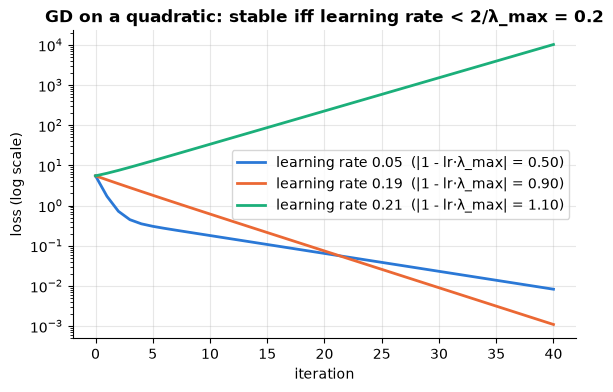

In [16]:
H = np.diag([1.0, 10.0])                             # Hessian with eigenvalues 1 and 10 -> limit 2/10 = 0.2
loss = lambda th: 0.5 * th @ H @ th
fig, ax = plt.subplots(figsize=(6.5, 4))
for lr in [0.05, 0.19, 0.21]:
    th = np.array([1.0, 1.0]); hist = [loss(th)]
    for _ in range(40):
        th = th - lr * H @ th                         # gradient step = forward Euler step on theta' = -H theta
        hist.append(loss(th))
    ax.semilogy(hist, label=f"learning rate {lr}  (|1 - lr·λ_max| = {abs(1 - lr * 10):.2f})")
ax.set_xlabel("iteration"); ax.set_ylabel("loss (log scale)")
ax.set_title("GD on a quadratic: stable iff learning rate < 2/λ_max = 0.2"); ax.legend(); plt.show()

**What just happened?** With learning rate 0.19 the loss still falls (slowly, because $|1 - 0.19 \times 10| = 0.9$ is close to 1); at 0.21 it explodes, exactly as the Euler stability analysis predicts. The small learning rate 0.05 is safe but ends up *slowest*: along the flat direction (eigenvalue 1) each step only multiplies the error by $1 - 0.05 = 0.95$. The largest eigenvalue caps the learning rate while the smallest sets the speed, so the ratio $\lambda_{\max}/\lambda_{\min}$ (the condition number) controls how hard the problem is. The same reasoning explains learning-rate warm-up and the "edge of stability" behaviour studied in deep-learning research.

**2. Gradient checking.** Every new layer or loss written by hand should be tested against central differences in float64, using a relative error $|g_{\text{auto}} - g_{\text{fd}}| / \max(|g_{\text{auto}}|, |g_{\text{fd}}|)$; values around $10^{-7}$ or smaller are healthy. [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) shows a production example and [`11_matrix_calculus_and_autodiff_from_scratch.ipynb`](11_matrix_calculus_and_autodiff_from_scratch.ipynb) uses it to verify an autodiff engine.

**3. Expected values for probabilistic forecasts.** A probabilistic forecaster outputs a *distribution* of demand $D$, but a business needs a single number, such as expected units sold, $\mathbb{E}[\min(D, S)]$ with stock $S$. That expectation is an integral. For $D \sim \mathcal{N}(\mu, \sigma^2)$ we can compute it with `quad`, with **Gauss–Hermite quadrature** (the Gauss rule designed for a Gaussian weight), or with Monte Carlo, and compare with the closed form $S - \sigma\,[z\Phi(z) + \varphi(z)]$, $z = (S - \mu)/\sigma$.

In [17]:
mu, sigma, S = 100.0, 20.0, 110.0
sold = lambda d: np.minimum(d, S)                         # units sold given demand d
z = (S - mu) / sigma
exact_sold = S - sigma * (z * stats.norm.cdf(z) + stats.norm.pdf(z))

q_val, _, q_info = integrate.quad(lambda d: sold(d) * stats.norm.pdf(d, mu, sigma), -np.inf, np.inf,
                                  full_output=True)[:3]
rows = [{"method": "closed form", "estimate": exact_sold, "f evaluations": 0}]
rows.append({"method": "scipy quad", "estimate": q_val, "f evaluations": q_info["neval"]})
for n in [5, 20, 80]:
    xg, wg = np.polynomial.hermite_e.hermegauss(n)        # nodes/weights for weight exp(-x²/2)
    gh = (wg * sold(mu + sigma * xg)).sum() / math.sqrt(2 * math.pi)
    rows.append({"method": f"Gauss-Hermite, {n} nodes", "estimate": gh, "f evaluations": n})
for n in [1_000, 100_000]:
    rows.append({"method": f"Monte Carlo, {n:,} samples", "estimate": sold(rng.normal(mu, sigma, n)).mean(),
                 "f evaluations": n})
df_ev = pd.DataFrame(rows); df_ev["abs error"] = (df_ev["estimate"] - exact_sold).abs()
df_ev.style.format({"estimate": "{:.6f}", "abs error": "{:.2e}"})

,method,estimate,f evaluations,abs error
0,closed form,96.044069,0,0.00e+00
1,scipy quad,96.044069,1290,1.58e-08
2,"Gauss-Hermite, 5 nodes",95.669053,5,3.75e-01
3,"Gauss-Hermite, 20 nodes",96.055858,20,1.18e-02
4,"Gauss-Hermite, 80 nodes",96.085957,80,4.19e-02
5,"Monte Carlo, 1,000 samples",97.041091,1000,9.97e-01
6,"Monte Carlo, 100,000 samples",96.083791,100000,3.97e-02


**What just happened?** All methods agree with the closed form, but look at the error column: Gauss–Hermite converges more slowly than its reputation suggests here, because $\min(d, S)$ has a **kink** at $d = S$ and Gauss rules assume smoothness. Adaptive `quad` handles it well, and Monte Carlo behaves as the $1/\sqrt n$ law predicts. Choosing a quadrature rule that matches the smoothness of the integrand matters in practice.

**4. Other places these methods appear in AI.**
- **Root finding:** Newton steps inside logistic-regression solvers (IRLS), line searches in L-BFGS, calibrating a classifier threshold.
- **Interpolation:** learning-rate schedules, image resizing (bilinear / bicubic interpolation in `torch.nn.functional.interpolate`), and spline-based models such as GAMs and Kolmogorov–Arnold networks.
- **ODE solvers:** diffusion models generate images by solving an ODE or SDE backwards in time; faster samplers (DDIM, DPM-Solver) are higher-order ODE solvers.
- **Monte Carlo:** dropout-based uncertainty, MCMC in [`07_bayesian_ml.ipynb`](07_bayesian_ml.ipynb), policy-gradient estimates in reinforcement learning.

---
## 11. Recap

- Two error sources pull in opposite directions: **truncation** shrinks with smaller steps, **round-off** grows with cancellation. A stable algorithm avoids subtracting nearly equal large numbers.
- **Root finding:** bisection is slow but guaranteed (linear), Newton is fast near a simple root (quadratic) but can cycle or diverge, secant has order about 1.618; use a bracketing hybrid such as `brentq` in practice.
- **Interpolation:** one polynomial through $n+1$ points is unique; equally spaced high-degree interpolation suffers **Runge's phenomenon**; use Chebyshev nodes or **cubic splines** ($O(n)$ tridiagonal solve).
- **Differentiation:** forward $O(h)$, central $O(h^2)$, best steps about $10^{-8}$ and $10^{-5}$ in float64; the complex step and autodiff avoid cancellation.
- **Integration:** trapezoid $O(h^2)$, Simpson $O(h^4)$, Gauss–Legendre exact to degree $2n - 1$ and exponentially convergent for smooth integrands; adaptive methods put points where they are needed.
- **Monte Carlo** error is $\sigma/\sqrt n$ in any dimension.
- **ODEs:** Euler is order 1, RK4 order 4; explicit methods are stable only for $h$ below about $2/|\lambda|$; **stiff** problems need implicit methods (Radau, BDF).
- **Gradient descent is forward Euler** on gradient flow, so the learning rate must satisfy $\eta < 2/\lambda_{\max}(H)$.

---
## Practice problems

**1. (Easy)** How many bisection iterations guarantee an error below $10^{-6}$ on an interval of length 1? Does the answer depend on the function?

<details><summary>Show solution</summary>

```python
import math
def bisection_steps(width, tol):
    return math.ceil(math.log2(width / tol))
print(bisection_steps(1.0, 1e-6))          # 20

# check by running bisection on x^2 - 2 over [1, 2]
f = lambda x: x * x - 2
a, b, k = 1.0, 2.0, 0
while b - a >= 1e-6:
    m = (a + b) / 2
    a, b = (a, m) if f(a) * f(m) <= 0 else (m, b)
    k += 1
print(k)                                    # 20
assert k == bisection_steps(1.0, 1e-6) == 20
```
After $k$ steps the bracket has width $(b - a)/2^k$, so we need $2^k \ge 10^6$, i.e. $k \ge \log_2 10^6 \approx 19.93$, so **20 iterations**, regardless of the function.

</details>

**2. (Easy, conceptual)** Why is the central difference more accurate than the forward difference, and why does making $h$ smaller eventually make *both* worse?

<details><summary>Show solution</summary>

Taylor-expand $f(x \pm h)$: in $f(x+h) - f(x-h)$ the even-order terms (including $\tfrac{h^2}{2}f''$) cancel, so the central difference has truncation error $O(h^2)$ instead of $O(h)$. But both formulas subtract two nearly equal numbers, each carrying round-off of about $\varepsilon_{\text{mach}}|f|$, then divide by $h$, so round-off error grows like $\varepsilon_{\text{mach}}/h$. Total error = falling truncation + rising round-off, minimised at $h \approx \sqrt{\varepsilon}$ (forward) or $\varepsilon^{1/3}$ (central) in units of the function's scale.

</details>

**3. (Medium, coding)** Derive Newton's iteration for $\sqrt{a}$ and implement it. How many iterations from $x_0 = 1$ for $a = 2$?

<details><summary>Show solution</summary>

```python
def newton_sqrt(a, x0=1.0, tol=1e-15):
    x, steps = x0, 0
    while True:
        x_new = 0.5 * (x + a / x)            # Newton on f(x) = x^2 - a
        steps += 1
        if abs(x_new - x) <= tol * abs(x_new):
            return x_new, steps
        x = x_new

import math
for a in [2.0, 10.0, 1e6]:
    r, k = newton_sqrt(a)
    assert math.isclose(r, math.sqrt(a), rel_tol=1e-15)
    print(a, r, k)
```
With $f(x) = x^2 - a$, $f'(x) = 2x$, Newton's update is $x - \frac{x^2 - a}{2x} = \frac12\left(x + \frac{a}{x}\right)$ (the Babylonian / Heron method). For $a = 2$ from $x_0 = 1$ it converges in 6 iterations (the last one just confirms convergence). For $a = 10^6$ from $x_0 = 1$ it needs more iterations, because far from the root each step only roughly halves $x$ until it is close to $\sqrt a$, after which convergence is quadratic.

</details>

**4. (Medium, coding)** Verify experimentally that composite Simpson's rule is fourth order on $\int_0^\pi \sin x\,dx = 2$.

<details><summary>Show solution</summary>

```python
import numpy as np, math
def simpson(f, a, b, n):
    x = np.linspace(a, b, n + 1); y = f(x); h = (b - a) / n
    return h / 3 * (y[0] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum() + y[-1])

errors = [abs(simpson(np.sin, 0, math.pi, n) - 2.0) for n in [4, 8, 16, 32, 64]]
ratios = [errors[i] / errors[i + 1] for i in range(len(errors) - 1)]
print(np.round(ratios, 2))                 # [16.94 16.22 16.06 16.01] -> 16
assert all(15 < r < 17.5 for r in ratios)
```
Halving $h$ divides an $O(h^4)$ error by $2^4 = 16$. Measured ratios close to 16 confirm fourth-order convergence (for the trapezoid rule you would see 4).

</details>

**5. (Medium, coding)** Implement Heun's method (an explicit 2-stage Runge–Kutta method) and measure its order on $y' = y$.

<details><summary>Show solution</summary>

```python
import numpy as np, math
def heun(f, t0, y0, t_end, h):
    n = int(round((t_end - t0) / h)); t, y = t0, float(y0)
    for _ in range(n):
        k1 = f(t, y)
        k2 = f(t + h, y + h * k1)          # Euler predictor, then average the two slopes
        y += h / 2 * (k1 + k2); t += h
    return y

hs = np.array([0.1, 0.05, 0.025, 0.0125])
errs = [abs(heun(lambda t, y: y, 0, 1.0, 1, h) - math.e) for h in hs]
order = np.polyfit(np.log(hs), np.log(errs), 1)[0]
print(round(order, 2))                      # about 2
assert 1.9 < order < 2.1
```
Heun's method (explicit trapezoid, a 2-stage Runge–Kutta method) has global error $O(h^2)$.

</details>

**6. (Hard)** For $y' = -20y$, derive the largest stable forward-Euler step and confirm it numerically.

<details><summary>Show solution</summary>

```python
import numpy as np
lam = -20.0
def euler_final(h, t_end=2.0):
    y = 1.0
    for _ in range(int(round(t_end / h))):
        y = y + h * lam * y
    return y
for h in [0.05, 0.099, 0.101, 0.12]:
    print(h, abs(1 + h * lam), euler_final(h))
assert abs(euler_final(0.099)) < 1 and abs(euler_final(0.12)) > 1
```
Forward Euler gives $y_{n} = (1 + h\lambda)^n y_0$. This decays iff $|1 + h\lambda| < 1$, i.e. $-2 < h\lambda < 0$, so for $\lambda = -20$ we need $h < 2/20 = 0.1$. At $h = 0.099$ the solution decays (while oscillating); at $h = 0.12$ the factor is $|1 - 2.4| = 1.4$ and it grows. Note this limit is about *stability*; accuracy may require an even smaller $h$.

</details>

**7. (Hard)** Show numerically that 3-point Gauss–Legendre quadrature is exact for polynomials up to degree 5 but not 6. Why $2n - 1$?

<details><summary>Show solution</summary>

```python
import numpy as np
t, w = np.polynomial.legendre.leggauss(3)
for k in range(8):
    exact = 0.0 if k % 2 else 2.0 / (k + 1)        # integral of x^k over [-1, 1]
    approx = (w * t**k).sum()
    print(k, round(approx, 12), exact, "exact" if abs(approx - exact) < 1e-12 else "NOT exact")
assert all(abs((w * t**k).sum() - (0.0 if k % 2 else 2 / (k + 1))) < 1e-12 for k in range(6))
assert abs((w * t**6).sum() - 2 / 7) > 1e-3
```
The 3-point rule integrates $x^0, \dots, x^5$ exactly (degree $2n - 1 = 5$) and is wrong for $x^6$: it gives $0.24$ instead of $2/7 \approx 0.2857$. Reason: $2n$ free parameters (nodes and weights) can match $2n$ moment conditions.

</details>

---
## Further reading
- Burden, Faires and Burden, *Numerical Analysis*, 10th ed.: Ch. 1 (errors), Ch. 2 (root finding), Ch. 3 (interpolation and splines), Ch. 4 (differentiation and integration), Ch. 5 (initial value problems), Ch. 8 (approximation theory).
- Michael Heath, *Scientific Computing: An Introductory Survey*, revised 2nd ed. (SIAM, 2018): Ch. 5, 7, 8 and 9.
- Lloyd N. Trefethen, *Approximation Theory and Approximation Practice* (SIAM, 2019), for why Chebyshev nodes work.
- Hairer and Wanner, *Solving Ordinary Differential Equations II: Stiff and Differential-Algebraic Problems* (for stiffness in depth).
- Free online: Kong, Siauw and Bayen, *Python Programming and Numerical Methods* (UC Berkeley, free online textbook); the SciPy documentation for `scipy.optimize`, `scipy.integrate` and `scipy.interpolate` (https://docs.scipy.org/doc/scipy/).

## Next notebook
Continue with [`10_numerical_linear_algebra.ipynb`](10_numerical_linear_algebra.ipynb): LU, Cholesky and QR factorisations, conditioning, iterative solvers such as conjugate gradient, eigenvalue algorithms, sparse matrices and randomized SVD.